### Read in evaluation results of models

In [ ]:
import glob
import os
import pandas as pd

eval_results_folder_1 = "../results/large_ontix_save/run_Aug26"
eval_results_folder_2 = "../results/large_varix_save/run_Aug26"
eval_results_folder_3 = "../results/large_disentanglix_save/run_Aug26"




def load_eval_results(folder_path, run_name=None):
	evaluation_files = glob.glob(os.path.join(folder_path, '*_evaluation.csv'))
	all_results = dict()

	for file in evaluation_files:
		print(f"Loading evaluation results from file: {file}")
		data = pd.read_csv(file)
		if "varix" in folder_path:
			ontology_name = os.path.basename(file).replace('_evaluation.csv', '').replace('large_varix_holdout_', '').replace('_task', '').replace('_ontology', '')
			ontology_name = ontology_name
		elif "disentanglix" in folder_path:
			ontology_name = os.path.basename(file).replace('_evaluation.csv', '').replace('large_disentanglix_holdout_', '').replace('_task', '').replace('_ontology', '')
			ontology_name = ontology_name
		else:
			ontology_name = os.path.basename(file).replace('_evaluation.csv', '').replace('large_ontix_holdout_', '').replace('_task', '').replace('_ontology', '')
		if run_name is not None:
			data['run_name'] = run_name
		# print(f"Loaded evaluation results for ontology: {ontology_name} from file: {file}")
		all_results[ontology_name+"$"+run_name] = data

	return all_results

all_eval_results_1 = load_eval_results(eval_results_folder_1, run_name="run_Aug26")
all_eval_results_2 = load_eval_results(eval_results_folder_2, run_name="run_Aug26")
all_eval_results_3 = load_eval_results(eval_results_folder_3, run_name="run_Aug26")


all_eval_results = {
    **all_eval_results_1,
    **all_eval_results_2,
    **all_eval_results_3,
    }


Loading evaluation results from file: ../results/large_ontix_save/run_Aug26/large_ontix_holdout_Dim32_ClaudeOpus5_evaluation.csv
Loading evaluation results from file: ../results/large_ontix_save/run_Aug26/large_ontix_holdout_Dim16_KimiK3_evaluation.csv
Loading evaluation results from file: ../results/large_ontix_save/run_Aug26/large_ontix_holdout_Dim32_KimiK3_evaluation.csv
Loading evaluation results from file: ../results/large_ontix_save/run_Aug26/large_ontix_holdout_Dim16_GPT5.6_TerraPro_evaluation.csv
Loading evaluation results from file: ../results/large_ontix_save/run_Aug26/large_ontix_holdout_Dim16_ClaudeOpus5_evaluation.csv
Loading evaluation results from file: ../results/large_ontix_save/run_Aug26/large_ontix_holdout_Dim48_ClaudeOpus5_evaluation.csv
Loading evaluation results from file: ../results/large_ontix_save/run_Aug26/large_ontix_holdout_Dim48_KimiK3_evaluation.csv
Loading evaluation results from file: ../results/large_ontix_save/run_Aug26/large_ontix_holdout_Dim32_GPT5.6

### Create combined df for plotting

In [3]:
df_list = []
for ontology__run_name, eval_df in all_eval_results.items():
    eval_df['ontology_run'] = ontology__run_name.split('$')[0]
    if "varix" in ontology__run_name:
        eval_df['LLM'] = "Varix"
    elif "disentanglix" in ontology__run_name:
        eval_df['LLM'] = "Disentanglix"    
    else:
        eval_df['LLM'] = ontology__run_name.split('$')[0].split('_')[1]
        eval_df['DIM'] = ontology__run_name.split('$')[0].split('_')[0]

    df_list.append(eval_df)

combined_eval_df = pd.concat(df_list, ignore_index=True)
print(combined_eval_df)

print(sorted(combined_eval_df.ontology_run.unique().tolist()))

      cv_run score_split           CLINIC_PARAM       metric     value  \
0       CV_1        test        Task1_Monocytes  roc_auc_ovo  0.897356   
1       CV_2        test        Task1_Monocytes  roc_auc_ovo  0.914063   
2       CV_3        test        Task1_Monocytes  roc_auc_ovo  0.908680   
3       CV_1       train        Task1_Monocytes  roc_auc_ovo  0.924120   
4       CV_2       train        Task1_Monocytes  roc_auc_ovo  0.920635   
...      ...         ...                    ...          ...       ...   
10435   CV_2        test  high_level_stage_name  roc_auc_ovo  0.769580   
10436   CV_3        test  high_level_stage_name  roc_auc_ovo  0.773564   
10437   CV_1       train  high_level_stage_name  roc_auc_ovo  0.787219   
10438   CV_2       train  high_level_stage_name  roc_auc_ovo  0.783409   
10439   CV_3       train  high_level_stage_name  roc_auc_ovo  0.784114   

                       ML_ALG         ML_TYPE ML_TASK ML_SUBTASK   run_name  \
0          LogisticRegression  c

In [4]:
# Make column to categorical with specific order
combined_eval_df['ontology_run'] = pd.Categorical(combined_eval_df['ontology_run'],
												  categories=sorted(combined_eval_df['ontology_run'].unique().tolist()),
												  ordered=True)	

In [5]:
# Absolute Performance Increase PCA vs Latent
pca_df = combined_eval_df[(combined_eval_df['ML_TASK'] == 'PCA') ]
lat_df = combined_eval_df[(combined_eval_df['ML_TASK'] == 'Latent') ]

merged_df = pd.merge(pca_df, lat_df, on=['ML_ALG', 'CLINIC_PARAM','cv_run', 'score_split', 'ontology_run','run_name', 'LLM', 'DIM'], suffixes=('_PCA', '_Latent'))
merged_df['perf_overPCA_pp'] =  (merged_df['value_Latent'] - merged_df['value_PCA']) * 100

### Plot A: absolute performance

In [ ]:
import seaborn as sns

# Manuel order of ontology_run 
order_ontology_run = [
	"Dim16_Disentanglix",
 	"Dim16_Varix",
  	"Dim16_ClaudeOpus5",
  	"Dim16_KimiK3",
	"Dim16_GPT5.6_TerraPro",
	"Dim32_Disentanglix",
 	"Dim32_Varix",
	"Dim32_ClaudeOpus5",
  	"Dim32_KimiK3",
	"Dim32_GPT5.6_TerraPro",
	"Dim48_Disentanglix",	
	"Dim48_Varix",	
	"Dim48_ClaudeOpus5",
	"Dim48_KimiK3",
	"Dim48_GPT5.6_TerraPro"
]

merged_df['ontology_run'] = pd.Categorical(merged_df['ontology_run'], categories=order_ontology_run, ordered=True)

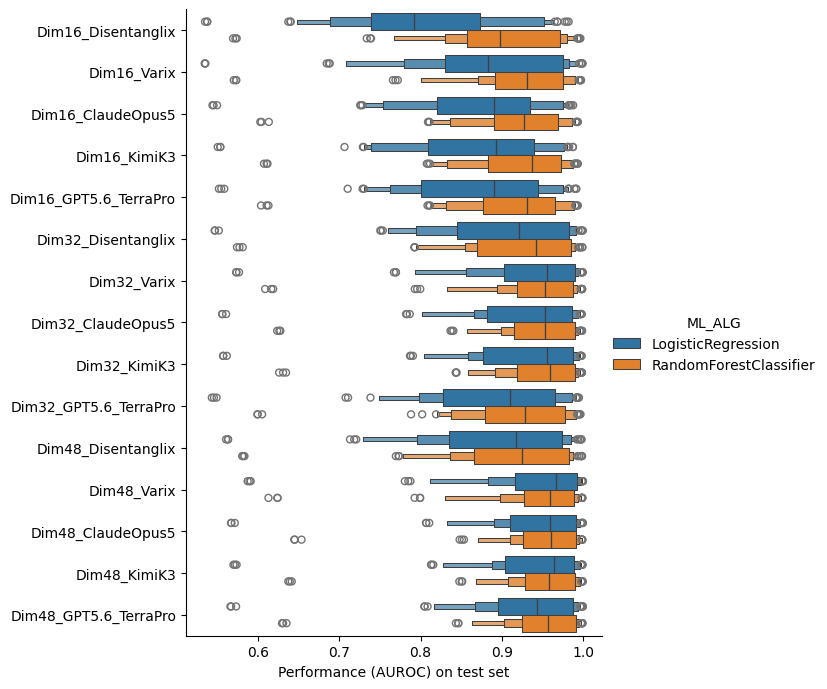

In [11]:
sns.catplot(data=merged_df[merged_df['score_split'] == "test"],
			kind = 'boxen',
			y='ontology_run', x='value_Latent', hue='ML_ALG',
			aspect=1,
			height=7,
   			legend_out=True,
			).set_xlabels("Performance (AUROC) on test set").set_ylabels("")

### Plot B: relative performance over PCA

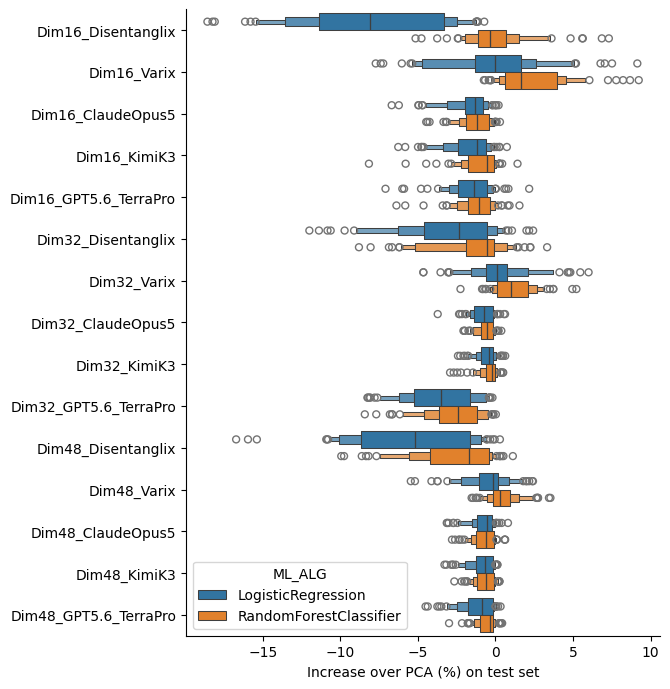

In [8]:
sns.catplot(data=merged_df[merged_df['score_split'] == "test"],
			kind = 'boxen',
			y='ontology_run', x='perf_overPCA_pp', hue='ML_ALG',
			# col='run_name',
			aspect=1,
			height=7,
   			legend_out=False,
			).set_xlabels("Increase over PCA (%) on test set").set_ylabels("")

### Supplement: detailed performance per task

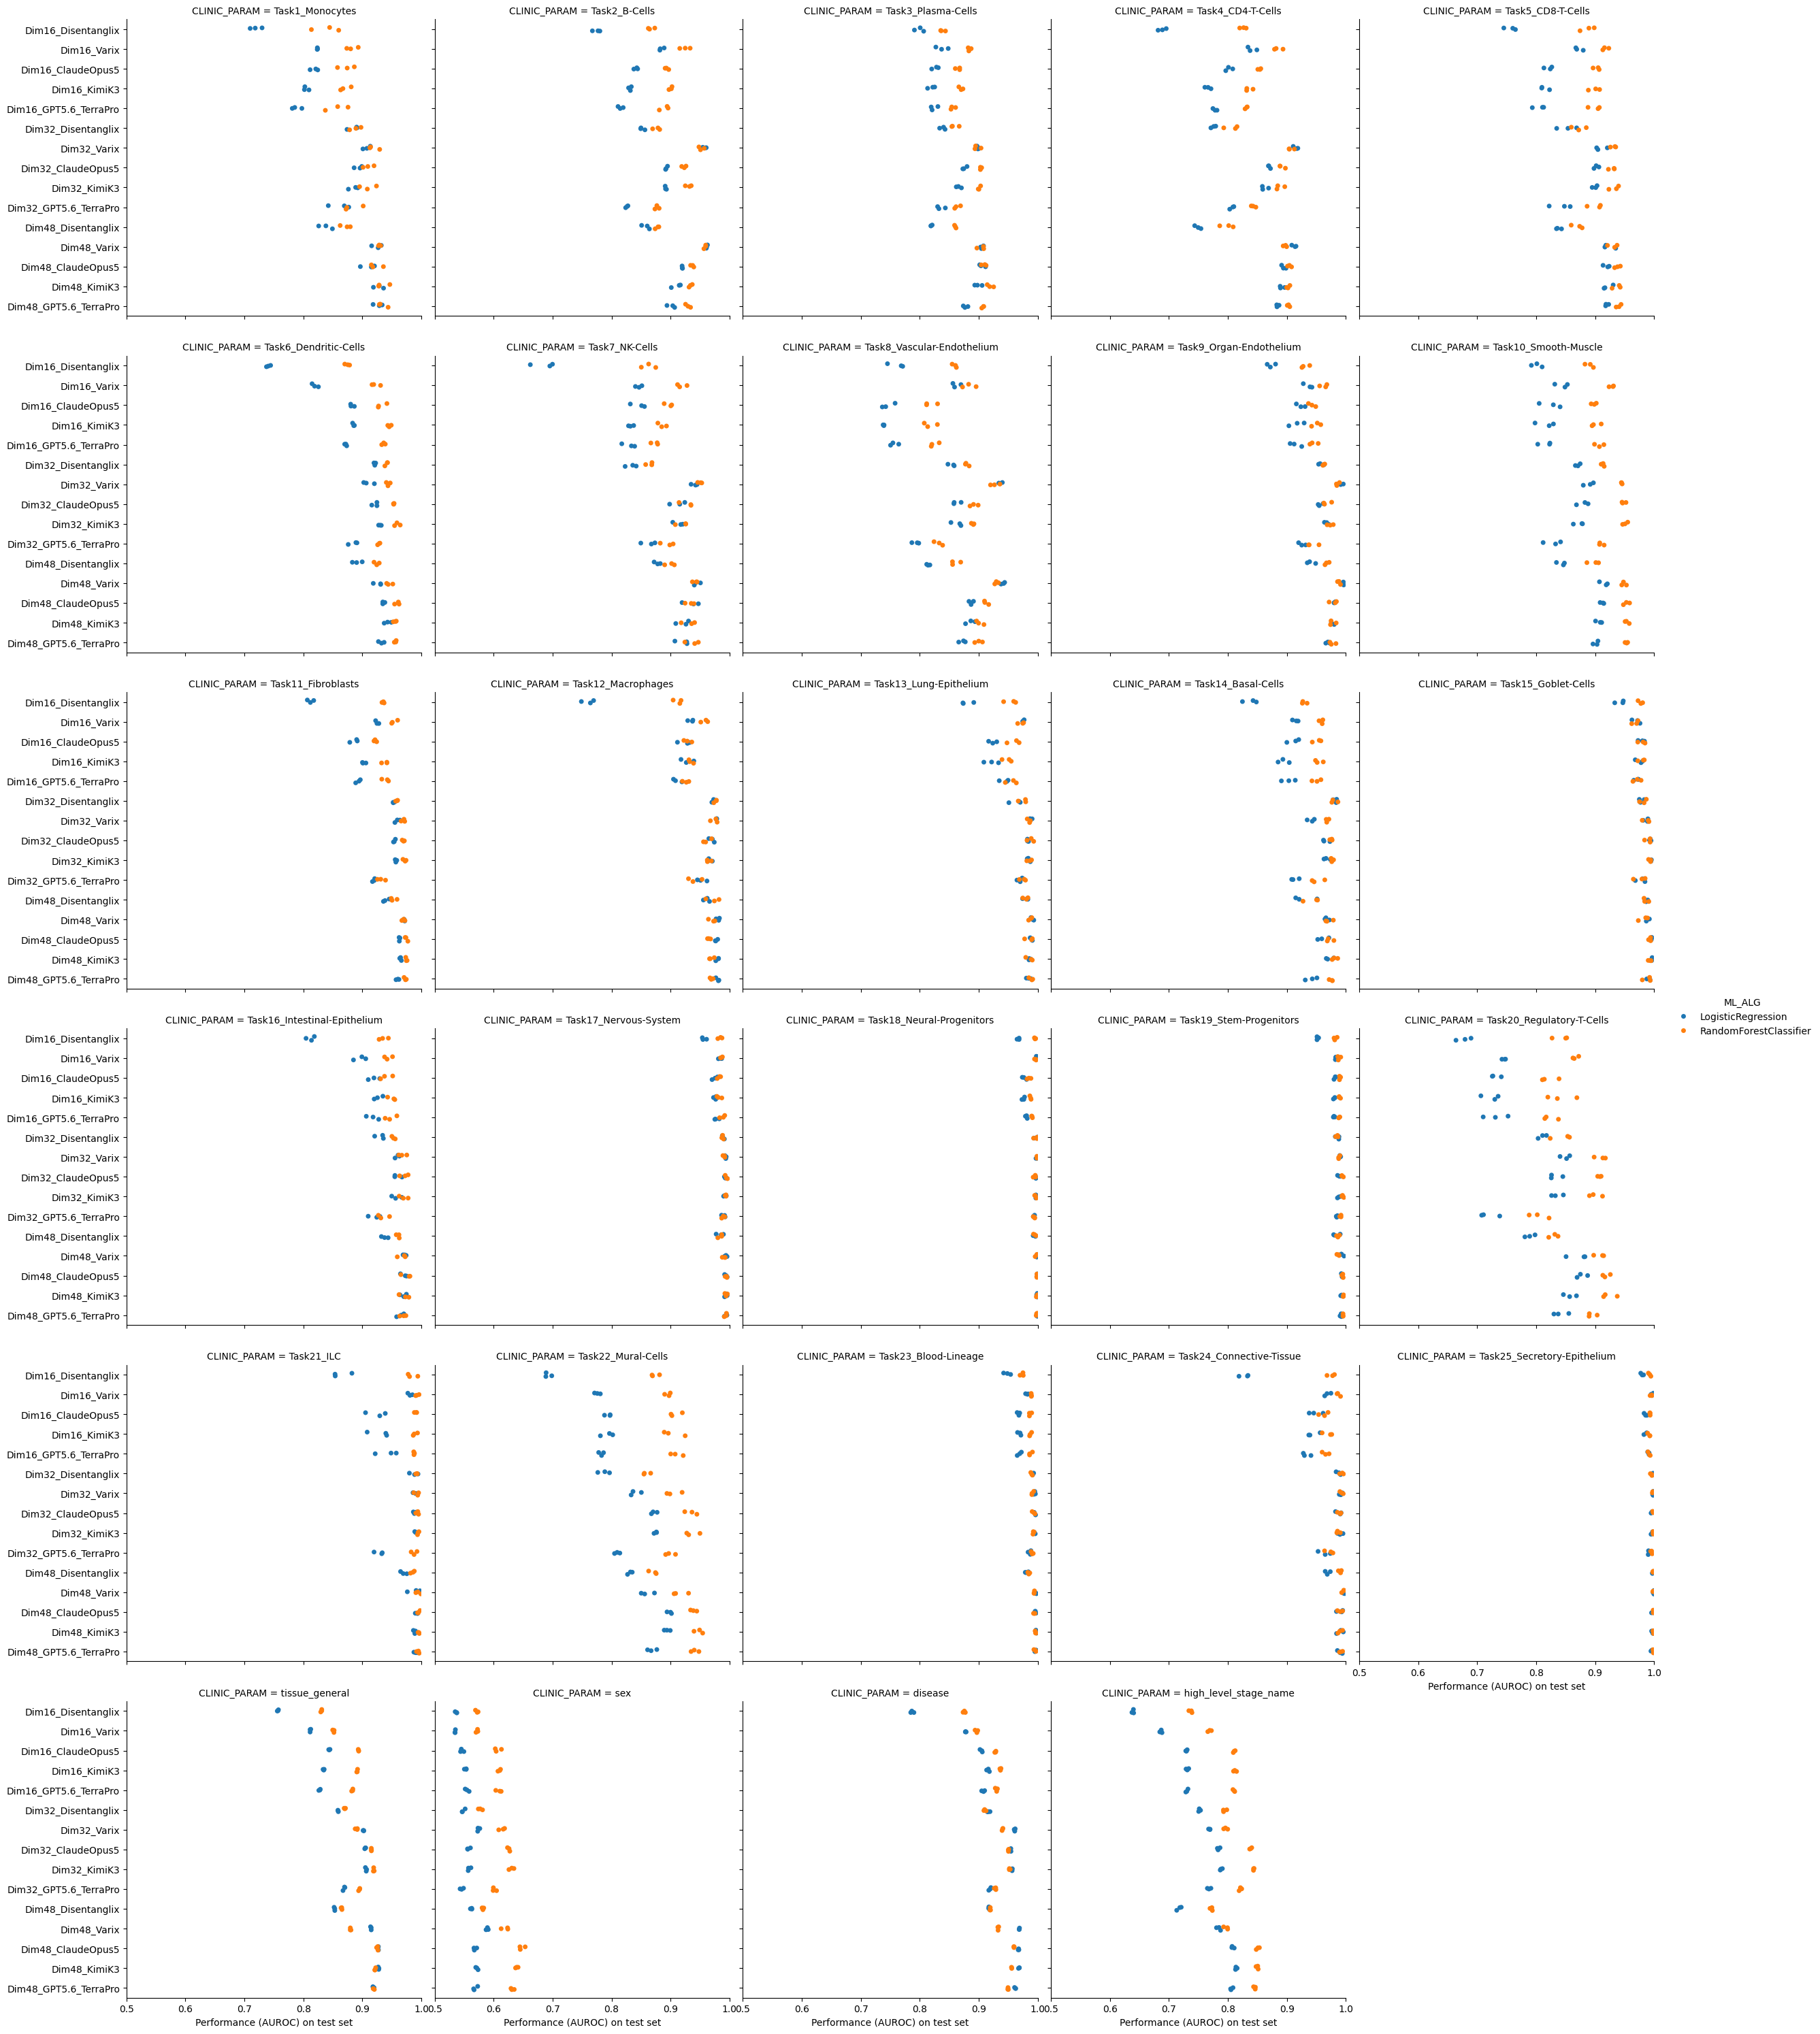

In [9]:
sns.catplot(data=merged_df[merged_df['score_split'] == "test"],
			kind = 'strip',
			y='ontology_run', x='value_Latent', hue='ML_ALG',
			col="CLINIC_PARAM", col_wrap=5).set(xlim=(0.5,1.0)).set_xlabels("Performance (AUROC) on test set").set_ylabels("")

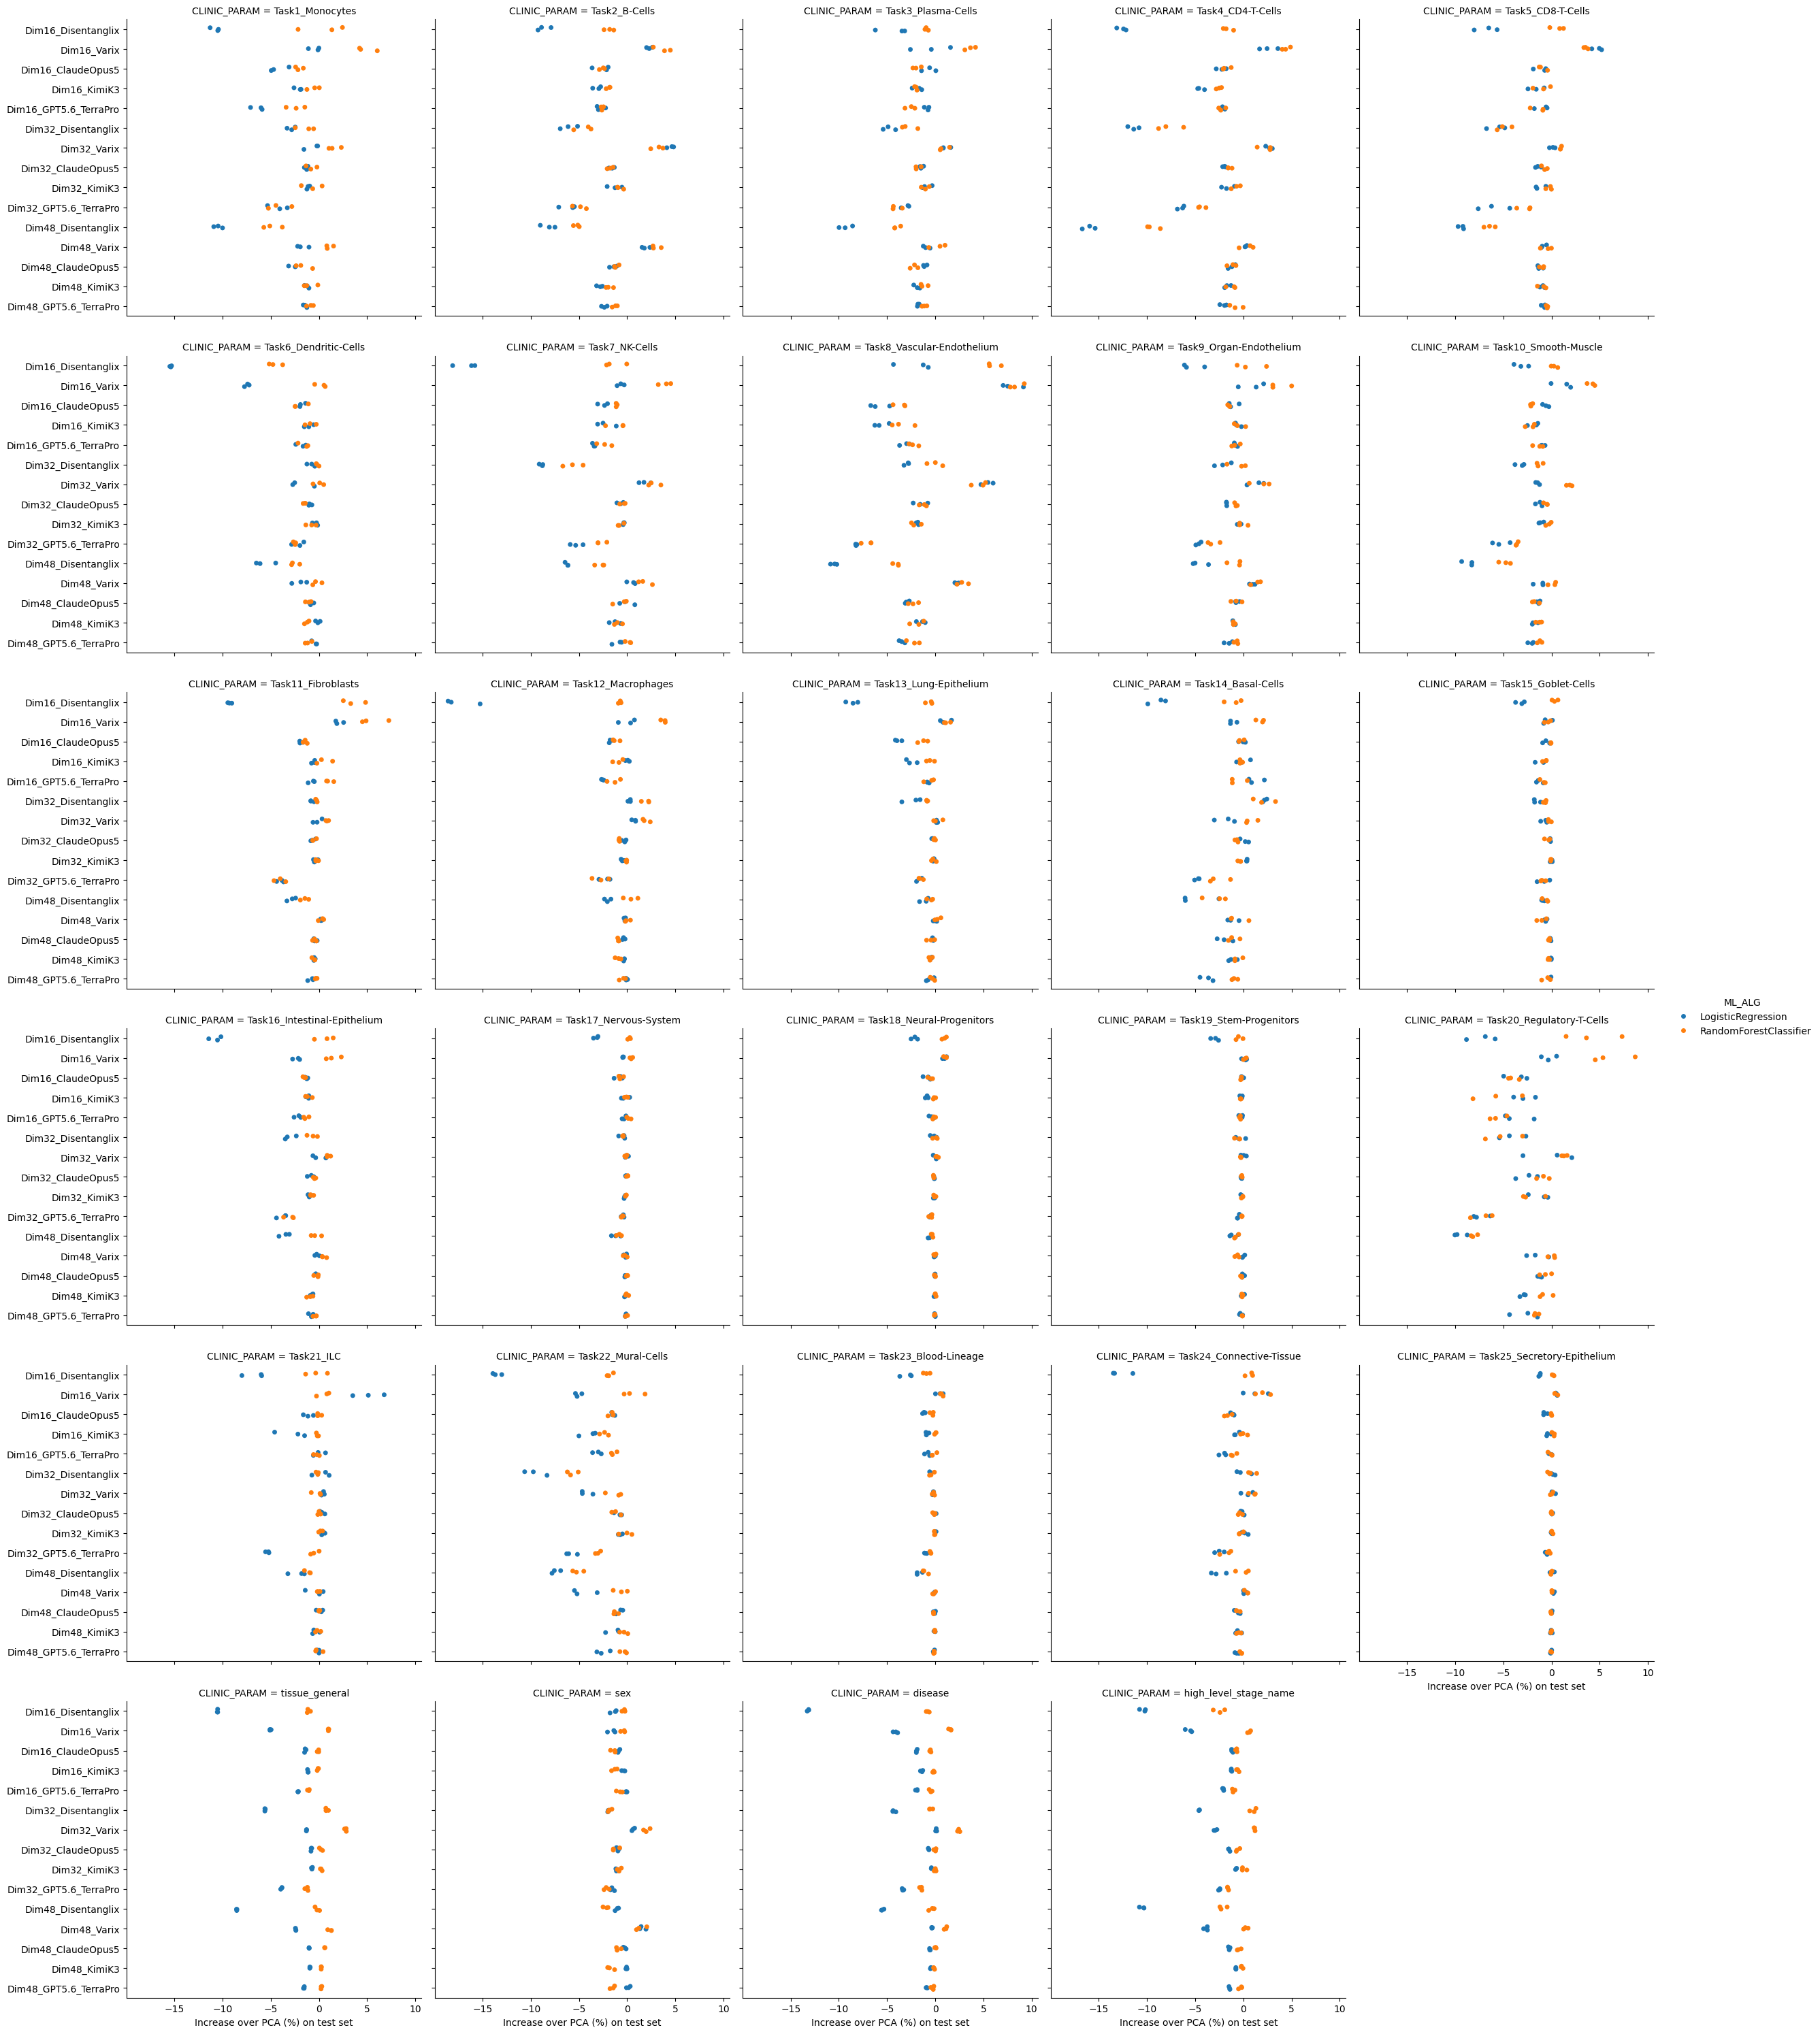

In [10]:
sns.catplot(data=merged_df[merged_df['score_split'] == "test"],
			kind = 'strip',
			y='ontology_run', x='perf_overPCA_pp', hue='ML_ALG',
			col="CLINIC_PARAM", col_wrap=5).set_xlabels("Increase over PCA (%) on test set").set_ylabels("")